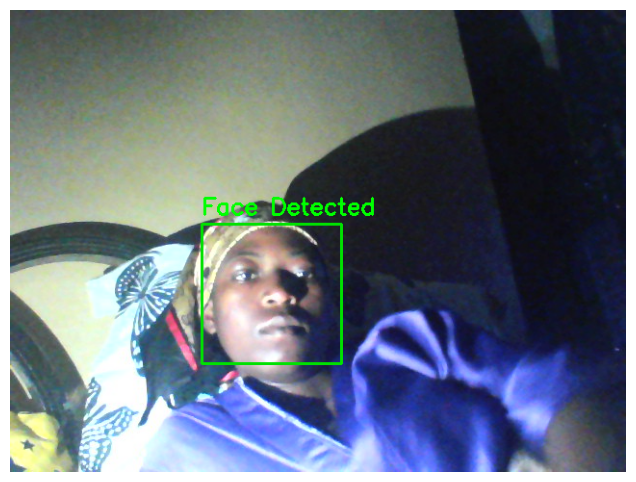

 Stream stoppped by user.


In [3]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import clear_output, display


face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'

)

cap = cv2.VideoCapture(0)
if not cap.isOpened():
    print("error:Could not open camera.")
else:
    print("Camera opened successfully. Press 'q' in the pop-up window to quit.")

try:

  while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("Error: can't recieve frame/ webcam stream ended.")
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(gray, 1.1, 4)


    for(x, y, w, h) in faces:
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 225, 0), 2)
        cv2.putText(
            frame, 
            'Face Detected', 
            (x, y-10), 
            cv2.FONT_HERSHEY_SIMPLEX,
              0.8,
             (0,255,0),
               2,
)
        frame_rgb = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(8,6))
        plt.imshow(frame_rgb)
        plt.axis('off')
        clear_output(wait=True)
        display(plt.gcf())
        plt.close()

except KeyboardInterrupt:
    print(" Stream stoppped by user.")

finally:
  cap.release()
  cv2.destroyAllWindows()

In [ ]:
import cv2
print(cv2.__version__)
print(hasattr(cv2,'CascadeClassifier'))

4.14.0
True


In [ ]:
import sys
import cv2
print("Python Executable",sys.executable)
print("cv2File Location:", getattr(cv2,'_file_','No file attribute'))
print("cv2 Attributes:", [attr for attr in dir(cv2) if not attr.startswith('_')])

Python Executable c:\Users\favour\AppData\Local\Programs\Python\Python312\python.exe
cv2File Location: No file attribute
cv2 Attributes: ['ACCESS_FAST', 'ACCESS_MASK', 'ACCESS_READ', 'ACCESS_RW', 'ACCESS_WRITE', 'ADAPTIVE_THRESH_GAUSSIAN_C', 'ADAPTIVE_THRESH_MEAN_C', 'ALGO_HINT_ACCURATE', 'ALGO_HINT_APPROX', 'ALGO_HINT_DEFAULT', 'ALIKED', 'ALIKED_Params', 'ALIKED_create', 'ANNINDEX_DIST_ANGULAR', 'ANNINDEX_DIST_DOTPRODUCT', 'ANNINDEX_DIST_EUCLIDEAN', 'ANNINDEX_DIST_HAMMING', 'ANNINDEX_DIST_MANHATTAN', 'ANNIndex', 'ANNIndex_DIST_ANGULAR', 'ANNIndex_DIST_DOTPRODUCT', 'ANNIndex_DIST_EUCLIDEAN', 'ANNIndex_DIST_HAMMING', 'ANNIndex_DIST_MANHATTAN', 'ANNIndex_create', 'AffineFeature', 'AffineFeature_create', 'Algorithm', 'AlignExposures', 'AlignMTB', 'Animation', 'AsyncArray', 'BFMatcher', 'BFMatcher_create', 'BORDER_CONSTANT', 'BORDER_DEFAULT', 'BORDER_ISOLATED', 'BORDER_REFLECT', 'BORDER_REFLECT101', 'BORDER_REFLECT_101', 'BORDER_REPLICATE', 'BORDER_TRANSPARENT', 'BORDER_WRAP', 'BackgroundS

In [4]:
import face_recognition
print('ok')

c:\Users\favour\AppData\Local\Programs\Python\Python312\Lib\site-packages\face_recognition_models\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


ok


In [7]:
import face_recognition
import os
import pickle

REGISTERED_FACES_PATH = 'registered_faces/'

def register_faces():
    known_encodings = []
    known_names = []

    for filename in os.listdir(REGISTERED_FACES_PATH):
        if filename.lower().endswith(('.jpg', '.png', '.jpeg')):
            name = os.path.splitext(filename)[0]
            image_path = os.path.join(REGISTERED_FACES_PATH, filename)
            image = face_recognition.load_image_file(image_path)
            encodings = face_recognition.face_encodings(image)

            if encodings:
                known_encodings.append(encodings[0])
                known_names.append(name)
                print(f'Registered: {name}')
            else:
                print(f'No face found in {filename} - skip')

    with open('encoding.pkl', 'wb') as f:
        pickle.dump((known_encodings, known_names), f)

    print(f'Total registered: {len(known_names)} faces')
    return known_encodings, known_names

register_faces()

Registered: Engr Goddy
Registered: Miss Esther
Registered: Miss Favour
Registered: MIss Sharon
Registered: Mme Kah Mercy
Registered: Mr CEO 2
Registered: Sir Ghany - Copy
Total registered: 7 faces


([array([-0.2016924 ,  0.2004977 ,  0.08391424,  0.02029002, -0.04407515,
         -0.16968113,  0.09149396, -0.12215497,  0.14111234, -0.01822975,
          0.27304044, -0.00823881, -0.19566303, -0.1472054 ,  0.092409  ,
          0.09208765, -0.18879348, -0.15230441, -0.10530701, -0.15463416,
          0.02789035, -0.00585145, -0.03909481,  0.07815427, -0.08234358,
         -0.22821774, -0.06525619, -0.15010919,  0.12252408, -0.16528933,
          0.11895613, -0.01995568, -0.21092634, -0.08392195, -0.05900536,
         -0.03177628,  0.05611533, -0.01747832,  0.16935533, -0.05234839,
         -0.12541083, -0.11312633,  0.00360539,  0.24997596,  0.15374343,
         -0.02672214,  0.01995423, -0.00332117,  0.07582545, -0.17070752,
         -0.03789386,  0.10565169,  0.14022575,  0.02933901, -0.00145047,
         -0.16802536, -0.05710848,  0.06939839, -0.20887817,  0.07893894,
          0.10496925, -0.12697811, -0.1348816 , -0.0229027 ,  0.24566349,
          0.09034153, -0.09476202, -0.

In [6]:
import cv2
import pickle
import face_recognition
import numpy as np

with open('encoding.pkl', 'rb') as f:
    known_encodings, known_names = pickle.load(f)

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    small = cv2.resize(frame, (0, 0), fx=0.25, fy=0.25)
    rgb_small = cv2.cvtColor(small, cv2.COLOR_BGR2RGB)

    face_locations = face_recognition.face_locations(rgb_small)
    face_encodings = face_recognition.face_encodings(rgb_small, face_locations)

    for face_encoding, face_location in zip(face_encodings, face_locations):
        matches = face_recognition.compare_faces(known_encodings, face_encoding, tolerance=0.5)
        distances = face_recognition.face_distance(known_encodings, face_encoding)
        best_match_index = np.argmin(distances)

        name = 'Unknown'
        if matches[best_match_index]:
            name = known_names[best_match_index]

        top, right, bottom, left = face_location
        top *= 4; right *= 4; bottom *= 4; left *= 4

        color = (0, 255, 0) if name != 'Unknown' else (0, 0, 255)
        cv2.rectangle(frame, (left, top), (right, bottom), color, 2)
        cv2.putText(frame, name, (left, top - 10),
                    cv2.FONT_HERSHEY_COMPLEX, 0.8, color, 2)

    cv2.imshow('Face Recognition', frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

KeyboardInterrupt: 

In [ ]:
import os
import pandas as pd
from datetime import datetime, time

FOLDER = 'attendance_record'
os.makedirs(FOLDER, exist_ok=True)


def get_attendance_file():
    """Path of today's CSV (recomputed each call, so it survives midnight)."""
    return os.path.join(FOLDER, f'attendance_{datetime.now().date()}.csv')


def load_marked(file):
    """Names already saved in the given file (empty set if no file yet)."""
    if os.path.exists(file):
        return set(pd.read_csv(file)['Name'])
    return set()


# Track who has been marked today (reloaded from the CSV, so restarts are safe)
current_file = get_attendance_file()
already_marked = load_marked(current_file)

   
CUTOFF = time(8, 0)  # change to your start time + grace period

def get_status():
    return "Present" if datetime.now().time() <= CUTOFF else "Late"
    
def mark_attendance(name):
    global current_file, already_marked

    if name == 'Unknown':
        return

    # New day? Switch to the new file and reset the tracker
    file = get_attendance_file()
    if file != current_file:
        current_file = file
        already_marked = load_marked(file)

    if name in already_marked:
        return

    already_marked.add(name)

    now = datetime.now()
    new_record = {
        'Name': name,
        'Date': now.strftime('%Y-%m-%d'),
        'Time': now.strftime('%H:%M:%S'),
        'Status': get_status(),
    }
    
    # Append one row; write the header only if the file is new
    pd.DataFrame([new_record]).to_csv(
        file,
        mode='a',
        header=not os.path.exists(file),
        index=False,
    )

    print(f"Marked present: {name} at {new_record['Time']}")

In [ ]:
import streamlit as st
import cv2
import pickle
import face_recognition
import numpy as np
import pandas as pd
from datetime import datetime
import os

st.title('Face Recognition Attendance System')
st.subheader('Traitz Acedemy | Hort 7.0')

#Load encodings
with open('encoding.pkl', 'rb') as f:
    known_encodings, known_names = pickle.load(f)

FRAME_WINDOW = st.image([])
attendance_display = st.empty()

already_marked = set()
cap = cv2.VideoCapture(0)

run = st.checkbox('Start Camera')

2026-10-08 15:21:05.922 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 15:21:06.375 
  command:

    streamlit run C:\Users\favour\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-08 15:21:06.378 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 15:21:06.382 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 15:21:06.386 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 15:21:06.392 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 15:21:06.394 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 15:21:06.406 Thr

In [8]:
import csv, os
from datetime import datetime

ENROLLED = ["Miss Favour", "Sir Ghany", "Mr CEO", "Miss Esther", "Engr Goddy", "Miss Sharon"]  # all expected people

def mark_absentees():
    today = datetime.now().strftime("%Y-%m-%d")
    path = f"attendance_record/attendance_{today}.csv"

    present = set()
    if os.path.exists(path):
        with open(path, newline="") as f:
            present = {row["Name"] for row in csv.DictReader(f)}

    with open(path, "a", newline="") as f:
        writer = csv.writer(f)
        if os.path.getsize(path) == 0:
            writer.writerow(["Name", "Date", "Time", "Status"])
        for name in ENROLLED:
            if name not in present:
                writer.writerow([name, today, "--:--:--", "Absent"])

mark_absentees()